In [4]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, pycolmap
from pathlib import Path

ROOT = Path.cwd().parents[1]          # adjust until ROOT is the Case_Study folder
RUNS = {f"{v}/{r}": ROOT / "data" / "colmap" / v / r
        for v in ["IMG_9175", "IMG_9176"]
        for r in ["run_full_local", "run_full_colab"]}
RUNS = {k: p for k, p in RUNS.items() if (p / "sparse_best").exists()}

rows = []
for k, p in RUNS.items():
    m = json.loads((p / "metrics.json").read_text()) if (p / "metrics.json").exists() else {}
    rows.append({"run": k, "registered": m.get("registered"), "total": m.get("total"),
                 "models": m.get("n_models"), "points": m.get("points3D"),
                 "reproj_px": m.get("mean_reproj_px"), "cuda": m.get("has_cuda"),
                 "timings_s": m.get("timings_s")})
pd.DataFrame(rows)

,run,registered,total,models,points,reproj_px,cuda,timings_s
0,IMG_9175/run_full_colab,200,200,1,94849,0.465448,False,"{'extract': 1526.8, 'match': 770.6, 'mapping':..."
1,IMG_9176/run_full_colab,200,200,2,101550,0.415126,False,"{'extract': 1332.7, 'match': 752.4, 'mapping':..."


IMG_9175/run_full_colab: cameras 200 | median step 0.3843 | max/median 2.4 | largest steps after idx [189 164 179 198 181]


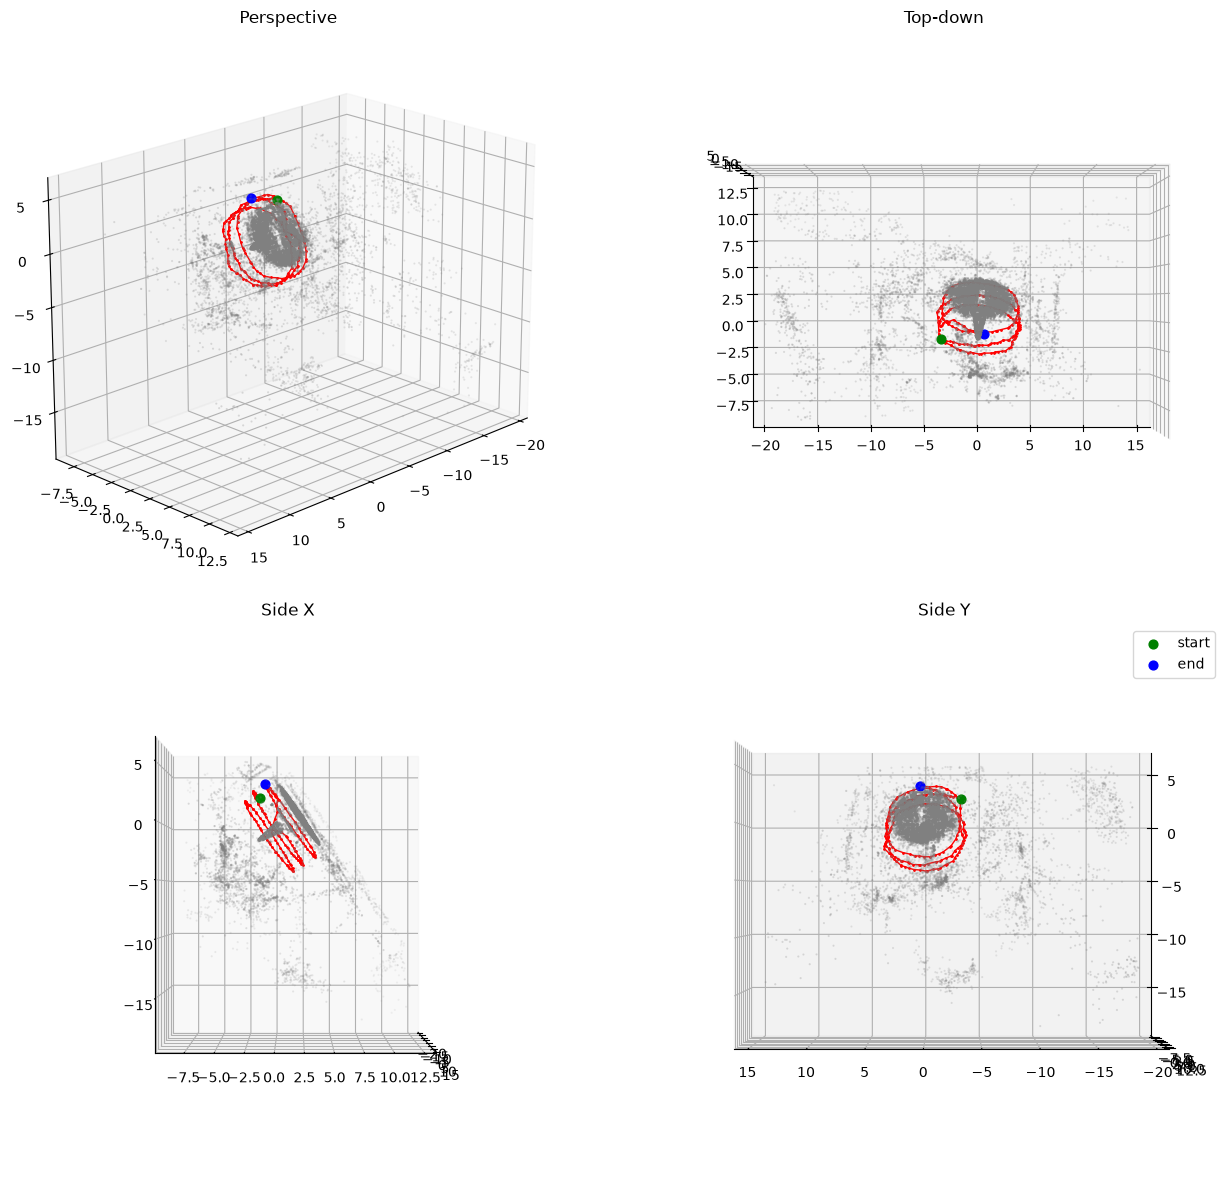

IMG_9176/run_full_colab: cameras 200 | median step 0.3658 | max/median 3.5 | largest steps after idx [122 123  56  66  89]


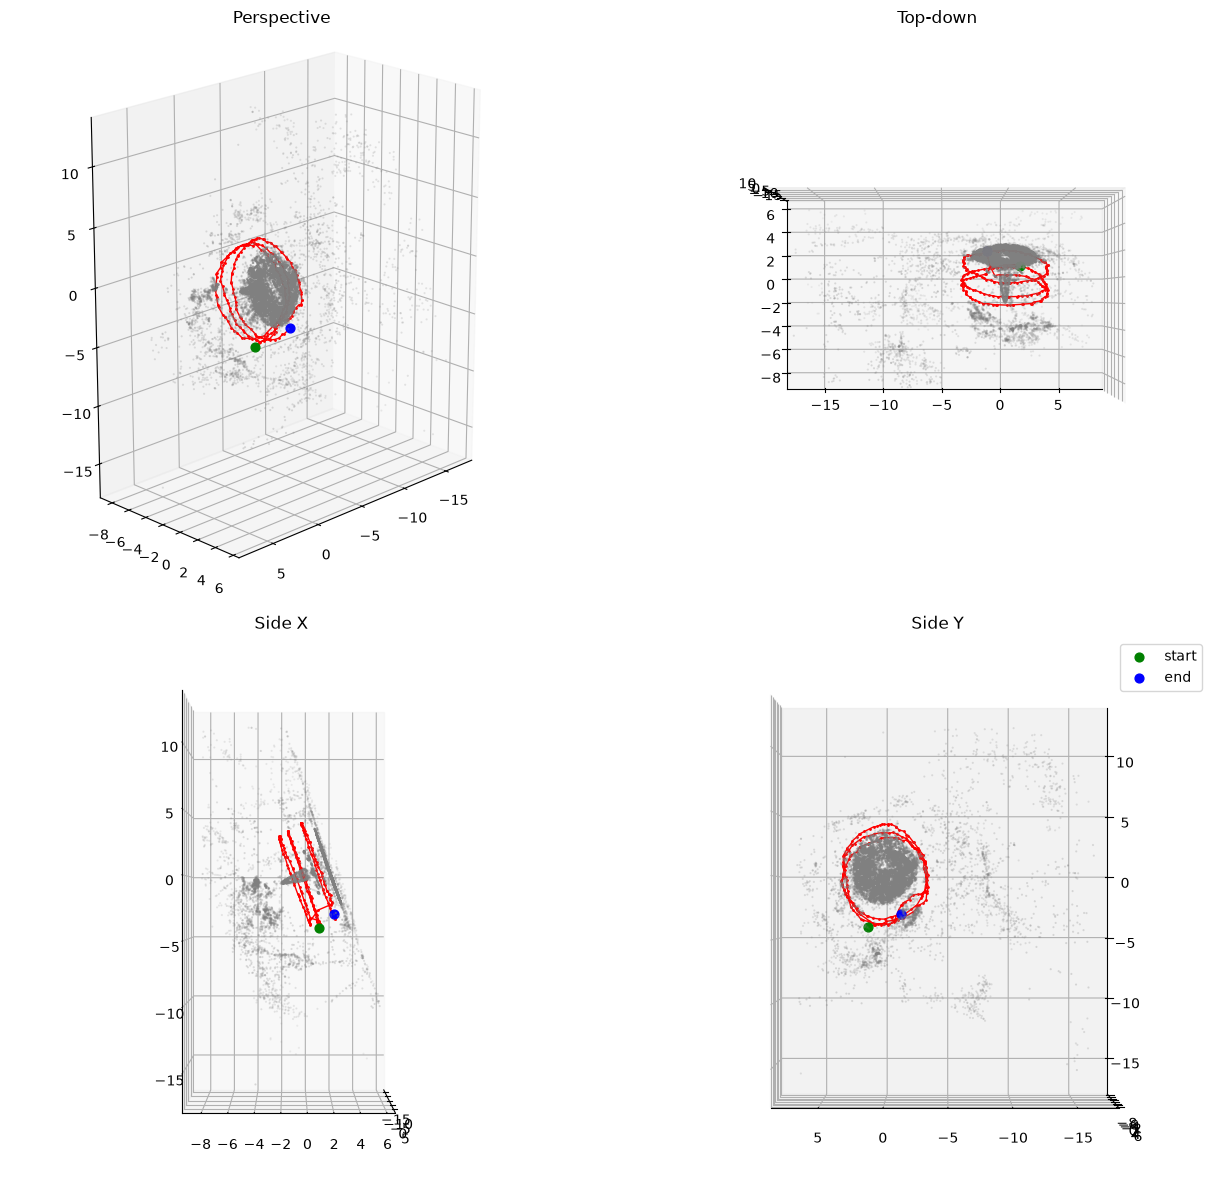

In [5]:
def check_path(run_dir):
    rec = pycolmap.Reconstruction(str(run_dir / "sparse_best"))
    df = pd.read_csv(run_dir / "camera_path.csv") if (run_dir / "camera_path.csv").exists() else None
    if df is None:
        raise FileNotFoundError("no camera_path.csv; re-run with the updated pipeline")
    C = df[["x", "y", "z"]].to_numpy()
    P = np.array([p.xyz for p in rec.points3D.values()])
    step = np.linalg.norm(np.diff(C, axis=0), axis=1)
    print(f"{run_dir.parent.name}/{run_dir.name}: cameras {len(C)} | median step {np.median(step):.4g} "
          f"| max/median {step.max()/np.median(step):.1f} | largest steps after idx {np.argsort(step)[-5:][::-1]}")
    lo, hi = np.percentile(P, 1, axis=0), np.percentile(P, 99, axis=0)
    Pc = P[np.all((P >= lo) & (P <= hi), axis=1)]
    fig = plt.figure(figsize=(14, 12))
    for i, (el, az, t) in enumerate([(20, 45, "Perspective"), (90, -90, "Top-down"),
                                     (0, 0, "Side X"), (0, 90, "Side Y")], 1):
        ax = fig.add_subplot(2, 2, i, projection="3d")
        ax.scatter(*Pc[::5].T, s=0.3, c="gray", alpha=0.5)
        ax.plot(*C.T, "r.-", ms=2, lw=1)
        ax.scatter(*C[0], c="green", s=40, label="start")
        ax.scatter(*C[-1], c="blue", s=40, label="end")
        ax.set_box_aspect(np.ptp(np.vstack([Pc, C]), axis=0))
        ax.view_init(elev=el, azim=az); ax.set_title(t)
    ax.legend(); plt.tight_layout()
    plt.savefig(run_dir / "camera_path.png", dpi=120); plt.show()

for k, p in RUNS.items():
    check_path(p)

In [6]:
for k, p in RUNS.items():
    r = pycolmap.Reconstruction(str(p / "sparse_best"))
    for c in r.cameras.values():
        print(k, c)
    m = json.loads((p / "metrics.json").read_text()) if (p / "metrics.json").exists() else {}
    print("   unregistered:", m.get("unregistered"))

IMG_9175/run_full_colab Camera(camera_id=1, model=OPENCV, width=1080, height=1920, params=[874.61407995239665, 875.49661186662377, 540, 960, -0.0029183297429343949, -7.0816475343399876e-05, -0.00016006273466317634, 4.2788254606412604e-05] (fx, fy, cx, cy, k1, k2, p1, p2))
   unregistered: []
IMG_9176/run_full_colab Camera(camera_id=1, model=OPENCV, width=1080, height=1920, params=[837.51093770816192, 839.14488204689576, 540, 960, -0.0033846096528979777, 0.00018191643624194007, -0.00023586229124371522, -9.9115563247467915e-05] (fx, fy, cx, cy, k1, k2, p1, p2))
   unregistered: []
